<a href="https://colab.research.google.com/github/Vitela-debug/Colab_S1_Clase-de-progralaci-n_273522_TVB/blob/main/PracticaRegresionLinealMultiple_273522.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Vitela Barraza Tania
*   Matrícula: 273522

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [51]:
# Tu código aquí


# ==========================================
# 1. Carga de datos y biblioteca
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
import scipy.stats as stats
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import statsmodels.api as sm

from google.colab import drive
drive.mount('/content/drive')

# ==========================================
# 2. Cargar el archivo
# ==========================================
ruta = '/content/drive/MyDrive/Unidad02/advertising.csv'
df = pd.read_csv(ruta)

# ==========================================
# 3. Mostrar las primeras filas
# ==========================================
print("Primeras 5 filas del DataFrame:")
display(df.head())

# ==========================================

# 4. Estadísticas descriptivas
print("Estadísticas descriptivas:")
display(df.describe())

# Información general
print("Información del DataFrame:")
df.info()

# Valores faltantes
print("\nValores faltantes por columna:")
print(df.isnull().sum())


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Primeras 5 filas del DataFrame:


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


Estadísticas descriptivas:


,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Valores faltantes por columna:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64


---
---
* El codigo del ejercicio 1 utiliza pd.read_csv() para cargar el archivo, df.head() para mostrar las primeras 5 filas, df.describe() para obtener estadísticas descriptivas, df.info() para revisar la estructura y los tipos de datos, y df.isnull().sum() para identificar valores faltantes. Así puedo conocer y revisar los datos antes de analizarlos.
---
---

## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

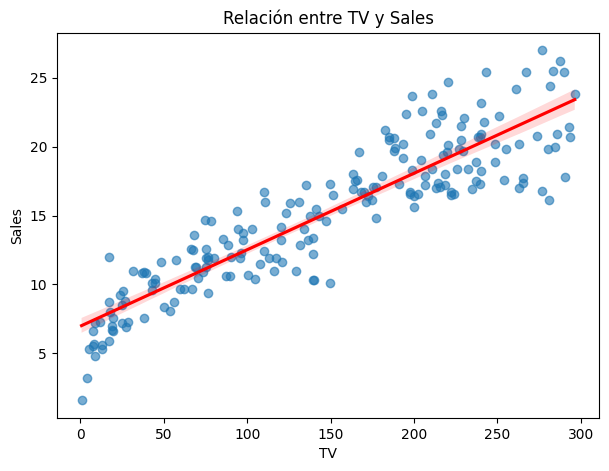

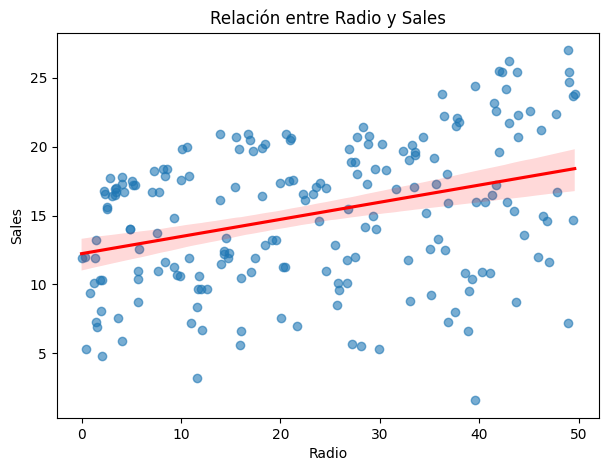

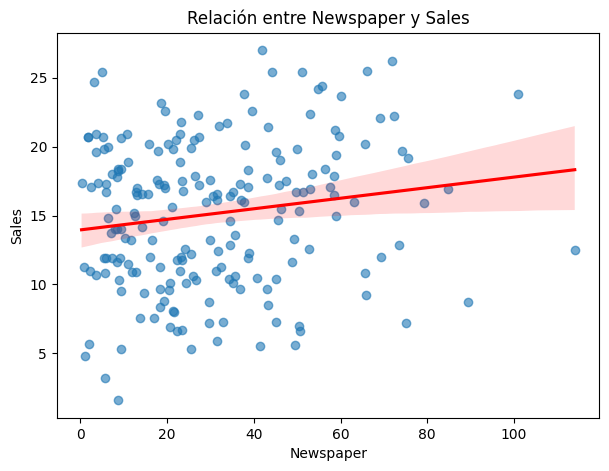

In [40]:
#1. Gráficos de dispersión


variables = ['TV', 'Radio', 'Newspaper']

for variable in variables:
    plt.figure(figsize=(7, 5))
    sns.regplot(data=df, x=variable, y='Sales',
                scatter_kws={'alpha': 0.6},
                line_kws={'color': 'red'})
    plt.title(f'Relación entre {variable} y Sales')
    plt.xlabel(variable)
    plt.ylabel('Sales')
    plt.show()

- TV vs. Sales: Se observa una relación lineal positiva fuerte. A mayor inversión en publicidad en televisión, mayores son las ventas.

- Radio vs. Sales: Existe una relación positiva moderada. Las ventas tienden a aumentar cuando aumenta la inversión en radio, aunque los datos están más dispersos.

- Newspaper vs. Sales: La relación positiva es débil. Los puntos están muy dispersos, por lo que la inversión en periódicos no muestra una relación lineal tan clara con las ventas.

Visualmente, TV es la variable que tiene la relación más fuerte con Sales, seguida de Radio y finalmente Newspaper. Esto sugiere que la publicidad en televisión está más relacionada con las ventas en comparación con los otros medios.

---
---
* El codigo del ejercicio 2 utiliza sns.regplot() para crear gráficos de dispersión y agregar una línea de tendencia entre las variables TV, Radio y Newspaper con Sales. La función plt.figure() crea el espacio para cada gráfica, plt.title() agrega el título y plt.xlabel() y plt.ylabel() indican los nombres de los ejes. Finalmente, plt.show() muestra cada gráfica. Esto me sirve para observar cómo se relaciona la inversión en publicidad con las ventas y comparar qué medio publicitario tiene mayor relación con ellas.
---
---

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.901208
Radio,0.054809,1.000000,0.354104,0.349631
Newspaper,0.056648,0.354104,1.000000,0.157960
Sales,0.901208,0.349631,0.157960,1.000000


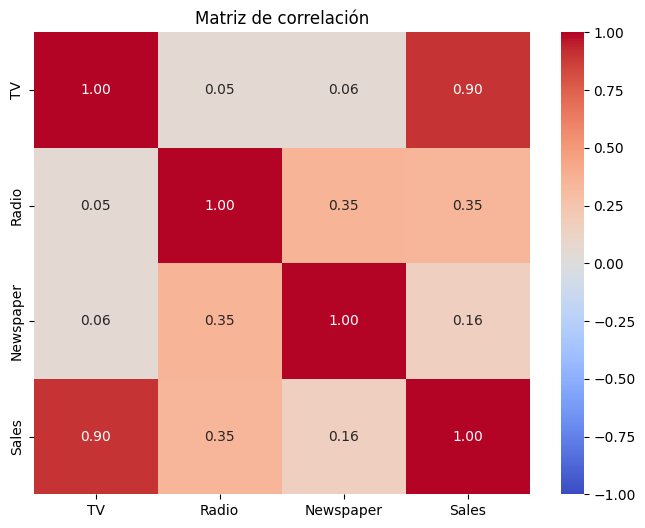

In [41]:
# Correlación y heatmap


# 1. Calcular la matriz de correlación
correlacion = df.corr(numeric_only=True)
display(correlacion)

# 2. Visualizar la matriz con un heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm',
            fmt='.2f', vmin=-1, vmax=1)
plt.title('Matriz de correlación')
plt.show()


 **3.
Responde: ¿Qué variables están más correlacionadas con Sales? ¿Hay correlación alta entre predictores**

1. ¿Qué variables están más correlacionadas con Sales?

TV (0.90): Tiene una correlación positiva muy fuerte con las ventas.

Radio (0.35): Tiene una correlación positiva moderada-baja.

Newspaper (0.16): Tiene una correlación positiva débil.

2. ¿Hay correlación alta entre predictores?

No, no hay correlaciones altas entre las variables independientes. La correlación más alta es entre Radio y Newspaper (0.35), mientras que TV y Radio (0.05) y TV y Newspaper (0.06) tienen correlaciones muy bajas.
Por lo anterioir, TV es la variable que más se relaciona con las ventas. Además, como las correlaciones entre los predictores son bajas, no parece haber un problema importante de multicolinealidad.

---
---
* El código del ejercicio 2 utiliza `df.corr()` para calcular la correlación entre las variables y `sns.heatmap()` para mostrar los resultados con colores. Sirve para identificar qué variables se relacionan más con las ventas y comprobar si existe una correlación alta entre los predictores.
---
---

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

,Variable,VIF
0,TV,1.004611
1,Radio,1.144952
2,Newspaper,1.145187


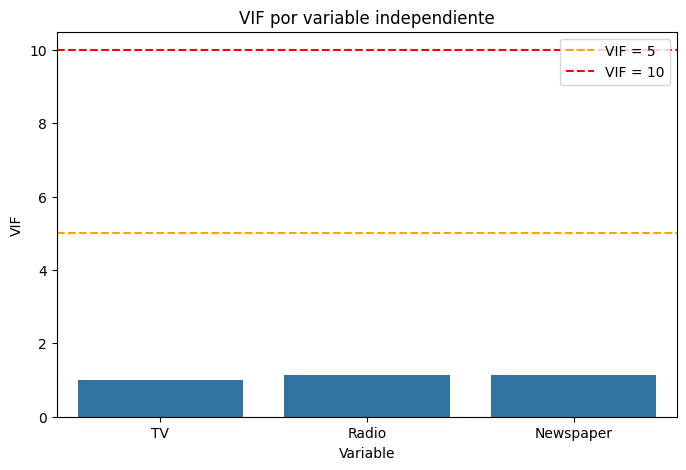

In [42]:
#Multicolinealidad

# Seleccionar las variables independientes
X = df[['TV', 'Radio', 'Newspaper']]

# 1. Calcular el VIF de cada predictor
vif = pd.DataFrame()
vif['Variable'] = X.columns
vif['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

display(vif)

# 2. Crear gráfica de barras
plt.figure(figsize=(8, 5))
sns.barplot(data=vif, x='Variable', y='VIF')
plt.axhline(5, color='orange', linestyle='--', label='VIF = 5')
plt.axhline(10, color='red', linestyle='--', label='VIF = 10')
plt.title('VIF por variable independiente')
plt.legend()
plt.show()

**3. Interpreta si hay multicolinealidad:

¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?

¿Qué implicaciones tiene esto para el modelo?**

**1. ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?**

No. Todas las variables tienen valores VIF menores a 5 y a 10. TV tiene 1.00, Radio 1.14 y Newspaper 1.15.

**2. ¿Qué implicaciones tiene esto para el modelo?**

Esto significa que no existe un problema importante de multicolinealidad entre las variables independientes. Por lo tanto, el modelo puede estimar los efectos de cada variable con mayor estabilidad y confiabilidad.

 ---
 ---
 * El código del ejercicio 3 calcula el VIF de cada variable independiente para comprobar si existe multicolinealidad. Después, muestra los resultados en una tabla y una gráfica de barras para comparar los valores. Esto sirve para identificar si las variables están demasiado relacionadas entre sí y si podrían afectar la estabilidad del modelo.
 ---
 ---




## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [43]:
#1. Entrenamiento del Modelo (Todas las Variables Independientes)

# Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Entrenar el modelo
modelo = LinearRegression()
modelo.fit(X, y)

# 2. Mostrar intercepto y coeficientes
print("Intercepto:", modelo.intercept_)

for variable, coeficiente in zip(X.columns, modelo.coef_):
    print(f"Coeficiente de {variable}: {coeficiente:.4f}")

Intercepto: 4.625124078808653
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1070
Coeficiente de Newspaper: 0.0003


**3. Interpreta cada uno: ¿Qué significa cada uno de los coeficientes en términos de ventas?**

- Intercepto (4.6251): Si no se invierte en publicidad en TV, Radio ni Newspaper, las ventas estimadas serían de 4.6251 unidades.

- TV (0.0544): Por cada unidad adicional invertida en publicidad televisiva, las ventas aumentan aproximadamente 0.0544 unidades, manteniendo constantes las demás variables.

- Radio (0.1070): Por cada unidad adicional invertida en radio, las ventas aumentan aproximadamente 0.1070 unidades, manteniendo constantes las demás variables.

- Newspaper (0.0003): Por cada unidad adicional invertida en periódicos, las ventas aumentan aproximadamente 0.0003 unidades, manteniendo constantes las demás variables.

Conclusión: Radio tiene el mayor coeficiente, seguido de TV, mientras que Newspaper tiene un efecto estimado muy pequeño sobre las ventas.

---
---
* El código del ejercicio 4.1 utiliza LinearRegression() para crear un modelo de regresión lineal múltiple y modelo.fit() para entrenarlo con las variables TV, Radio y Newspaper, con el objetivo de predecir las ventas. Después, muestra el intercepto y los coeficientes para conocer cómo influye cada tipo de publicidad en las ventas.
---
---

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

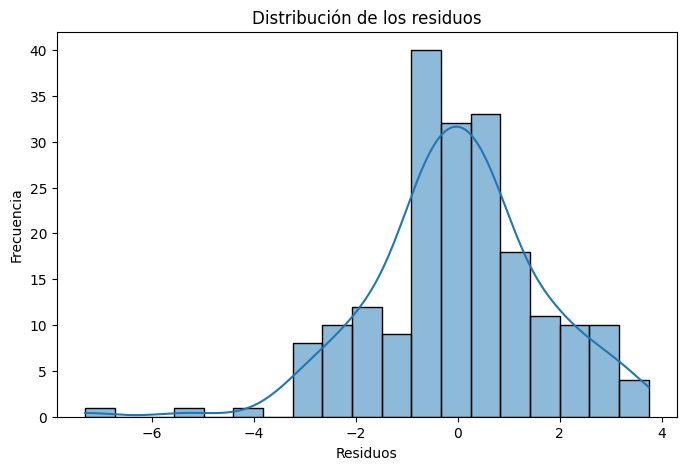

In [44]:
#Normalidad de los residuos

# 1. Calcular las predicciones y los residuos
y_pred = modelo.predict(X)
residuos = y - y_pred

#2.  Graficar histograma con KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos, kde=True)
plt.title('Distribución de los residuos')
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.show()

**3. ¿Los residuos parecen distribuirse normalmente?**


Según el histograma, los residuos no parecen seguir una distribución normal perfecta, aunque presentan cierta aproximación a una distribución de tipo campana.

Y se observan las siguientes características:

-Concentración central: la mayoría de los residuos se encuentran cerca de cero, lo cual es favorable.

-Asimetría: la distribución presenta una cola más larga hacia la izquierda, con algunos valores negativos extremos.

-Valores atípicos: se observan residuos alejados del centro, especialmente alrededor de −7 y −5.

-Forma de la distribución: aunque existe una concentración alrededor de cero, la distribución no es completamente simétrica.

---
---
* El código utiliza `modelo.predict(X)` para calcular las ventas que predice el modelo y residuos = y - y_pred para comparar las ventas reales con las estimadas. Por ejemplo, si las ventas reales son 20 y el modelo predice 18, el residuo es 2. Después, utiliza `sns.histplot(residuos, kde=True)` para crear un histograma con una curva que me ayuda a observar si los residuos tienen una distribución parecida a una campana y se concentran alrededor de cero. Esto sirve para revisar si se cumple el supuesto de normalidad de los residuos.
---
---

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

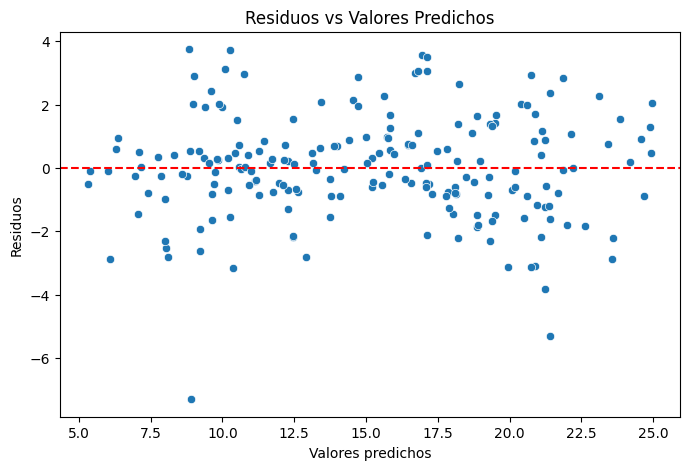

In [45]:
# Homocedasticidad
#1. Graficar residuos contra valores predichos
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuos)

# Línea de referencia en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuos vs Valores Predichos')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.show()

**2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?**

Al observar la gráfica de residuos contra valores predichos, no se cumple completamente el supuesto de homocedasticidad.

Los residuos se distribuyen alrededor de la línea horizontal cero, pero no presentan una dispersión totalmente uniforme. Se observa que, conforme aumentan los valores predichos, la variabilidad de los residuos parece incrementarse y aparecen algunos valores extremos.

---
---
* El código utiliza `plt.scatter(valores_predichos, residuos)` para crear una gráfica donde compara los valores predichos con los residuos. Después, con `plt.axhline(y=0, color='red', linestyle='--')`, agrega una línea roja que representa el cero y permite observar cómo se distribuyen los errores. Finalmente, con `plt.xlabel() `y `plt.ylabel() `coloca los nombres de los ejes y con `plt.title() `agrega el título. Esto permite identificar si los residuos se dispersan de manera aleatoria o si presentan algún patrón, para comprobar si se cumple la homocedasticidad.
---
---

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

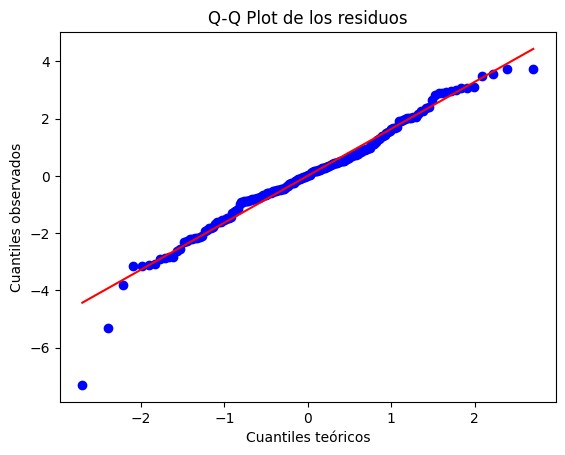

In [46]:
#1. Q-Q Plot

stats.probplot(residuos, dist="norm", plot=plt)
plt.title("Q-Q Plot de los residuos")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.show()

**Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.**

a) Alineación de los puntos:

Se observa que la mayoría de los puntos se encuentran aproximadamente alineados sobre la línea diagonal roja. Esto indica que los residuos siguen, en general, una distribución aproximadamente normal.

b) Desviaciones sistemáticas:

En los extremos del gráfico se observan algunas desviaciones respecto a la línea diagonal, especialmente en la cola izquierda, donde hay puntos bastante alejados. Esto puede indicar la presencia de colas pesadas y valores atípicos (outliers).


---
---
* El código realiza una gráfica Q-Q para comparar los residuos del modelo con una distribución normal. Utiliza `stats.probplot(residuos, dist="norm", plot=plt)` para mostrar los puntos y observar qué tan cerca están de la línea diagonal. Después, con `plt.title()` agrega el título y con `plt.xlabel()` y `plt.ylabel()` coloca los nombres de los ejes. Finalmente,` plt.show()` muestra la gráfica. Esto nos ayuda a identificar si los residuos siguen una distribución normal o si presentan alguna desviación.
---
---

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [47]:
#1 Evaluación del Modelo

# 2. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 3. Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 5. Obtener las predicciones
y_pred = modelo.predict(X_test)

# 6. Calcular las métricas
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# 7. Mostrar resultados
print("Evaluación del Modelo")
print("---------------------")
print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

Evaluación del Modelo
---------------------
MSE: 2.9077569102710896
RMSE: 1.7052146229349223
R²: 0.9059011844150826


**¿Qué nos dicen estas métricas sobre el ajuste del modelo?**

Las métricas indican que nuestro modelo tiene un buen ajuste, ya que el valor de R² es de 0.9059, lo que significa que el modelo logra explicar aproximadamente el 90.59% de la variación de las ventas. El MSE de 2.9077 y el RMSE de 1.7052 indican que los errores de las predicciones son relativamente bajos. En general, podemos decir que el modelo realiza buenas predicciones y que las variables TV, Radio y Newspaper ayudan a explicar las ventas, aunque todavía existe un pequeño margen de error.

---
---
* El código selecciona las variables TV, Radio y Newspaper para utilizarlas en la predicción de las ventas (Sales). Después, con `train_test_split()` divide los datos en una parte para entrenar el modelo y otra para probarlo. Utiliza `modelo.fit()` para entrenar la regresión lineal y `modelo.predict()` para obtener las predicciones. Finalmente, calcula el MSE, RMSE y R² para conocer qué tanto se equivoca el modelo, qué tan cerca están las predicciones de los valores reales y qué tan bien explica las ventas. Así podemos saber si nuestro modelo tiene un buen ajuste y qué tan confiables son sus predicciones.
---
---


### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

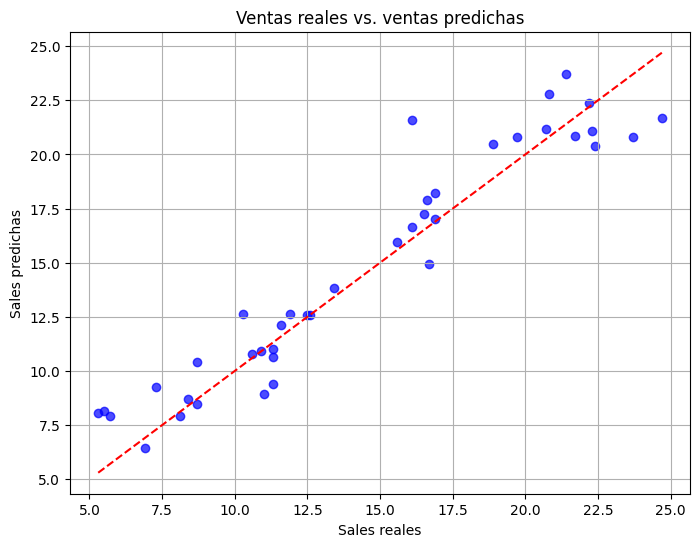

In [50]:
#Visualización de las Predicciones

#1.  Crear gráfico de dispersión
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, color='blue', alpha=0.7)

# Línea de referencia (predicción perfecta)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel('Sales reales')
plt.ylabel('Sales predichas')
plt.title('Ventas reales vs. ventas predichas')

plt.grid(True)
plt.show()

**3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?**

En la gráfica podemos observar la relación entre las ventas reales y las ventas predichas por el modelo de regresión lineal. Cada punto representa una observación del conjunto de datos de prueba.

La línea roja representa las predicciones perfectas, es decir, cuando las ventas predichas son iguales a las ventas reales.

Los puntos que están cerca de la línea roja indican que el modelo realiza predicciones precisas.

Los puntos que están alejados de la línea representan errores de predicción, que en su mayoria se presetan al inicio y al final de ventas reales.

Dado que los puntos se distribuyen cerca de la línea, significa que existe un buen ajuste del modelo.



---
---
* El código sirve para crear una gráfica que compara las ventas reales con las ventas predichas por nuestro modelo. Primero se utiliza` plt.scatter() `para mostrar los puntos azules que representan las ventas reales y las predichas. También agregamos una línea roja punteada que sirve como referencia para identificar qué tan precisas son las predicciones. Luego colocamos los nombres de los ejes, agregamos un título y una cuadrícula para facilitar la lectura. Finalmente, con `plt.show()` mostramos la gráfica y podemos observar qué tan bien está funcionando nuestro modelo.
---
---

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [53]:
#P-values

# Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

#  Agregar la constante al modelo
X = sm.add_constant(X)

#  Ajustar el modelo de regresión
modelo_sm = sm.OLS(y, X).fit()

#  Mostrar los resultados
print(modelo_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        00:37:19   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

**2. Interpreta los resultados:**

¿Qué variables tienen p-value menores a 0.05?
Las variables TV y Radio tienen valores p menores a 0.05, por lo tanto, son estadísticamente significativas.

La variable Newspaper tiene un valor p de 0.954, que es mayor a 0.05, por lo que no es estadísticamente significativa.

Conclusión (con tus propias palabras)
Los resultados muestran que la publicidad en TV y Radio tiene una relación significativa con las ventas, lo que significa que estas variables sí aportan información importante para explicar los resultados del modelo. En cambio, Newspaper no muestra una influencia significativa, ya que su valor p es mayor a 0.05. Por lo tanto, podemos decir que la televisión y la radio son los medios que tienen mayor importancia para explicar las ventas dentro de nuestro modelo, mientras que el periódico no aporta suficiente evidencia estadística de tener un efecto adicional.

---
---
* El código utiliza la librería statsmodels para realizar una regresión lineal y analizar cómo las variables TV, Radio y Newspaper se relacionan con las ventas (Sales). Con sm.add_constant(X) agrega una constante al modelo y con sm.OLS(y, X).fit() realiza el ajuste de la regresión. Finalmente, modelo_sm.summary() muestra una tabla con los resultados, donde podemos observar los coeficientes y los valores p para identificar qué variables tienen una relación significativa con las ventas y cuáles no.


---
---



##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

**5.1 Entrenamiento del Modelo (sin Multicolinealidad)**
Como en la Parte 3 se comprobó que ninguna variable independiente presenta multicolinealidad, se conservarán las tres variables: TV, Radio y Newspaper.

In [54]:
# 1. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 2. Entrenar el modelo
modelo_sin_multi = LinearRegression()
modelo_sin_multi.fit(X, y)

# 3. Mostrar intercepto y coeficientes
print("Intercepto:", modelo_sin_multi.intercept_)

for variable, coeficiente in zip(X.columns, modelo_sin_multi.coef_):
    print(f"Coeficiente de {variable}: {coeficiente:.4f}")

Intercepto: 4.625124078808653
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1070
Coeficiente de Newspaper: 0.0003


Interpretación:

El modelo conserva las tres variables independientes porque ninguna presenta valores VIF mayores a 5.

Los coeficientes obtenidos son:

TV: 0.0544

Radio: 0.1070

Newspaper: 0.0003

Esto indica que la inversión en televisión y radio tiene una relación positiva con las ventas, mientras que Newspaper presenta un efecto estimado muy pequeño.

---
---
* El código utiliza `LinearRegression()` para crear y entrenar un modelo de regresión lineal múltiple con las variables TV, Radio y Newspaper. Después, muestra el intercepto y los coeficientes para conocer cómo influye cada variable en las ventas.
---
---

**5.2 Normalidad de los residuos**

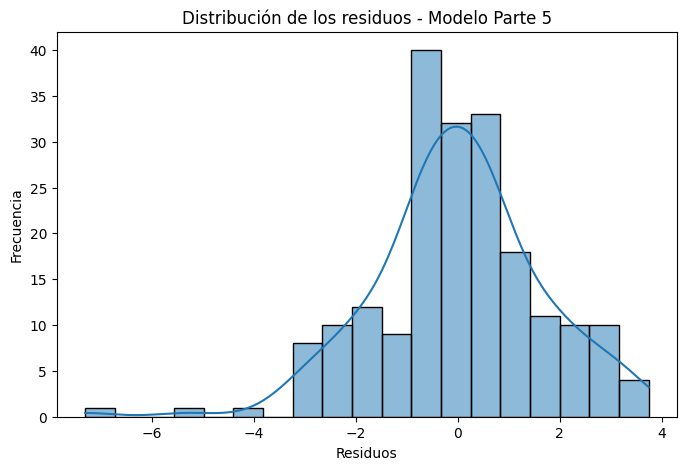

In [55]:
# 1. Obtener predicciones
y_pred_5 = modelo_sin_multi.predict(X)

# 2. Calcular residuos
residuos_5 = y - y_pred_5

# 3. Graficar histograma con KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos_5, kde=True)
plt.title('Distribución de los residuos - Modelo Parte 5')
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.show()

Interpretación:

Al observar el histograma, los residuos presentan una distribución aproximadamente similar a una campana, concentrándose principalmente alrededor de cero. Sin embargo, no siguen una distribución normal perfecta, ya que se observan algunas desviaciones y valores extremos.

Por lo tanto, podemos decir que el supuesto de normalidad se cumple de manera aproximada, aunque existen algunas pequeñas desviaciones.

---
---
* El código utiliza modelo_`sin_multi.predict(X)` para obtener las predicciones y calcula los residuos comparando los valores reales con los estimados. Después, utiliza `sns.histplot()` para crear un histograma con una curva KDE que permite observar si los residuos tienen una distribución aproximadamente normal.
---
---

**5.3 Homocedasticidad**

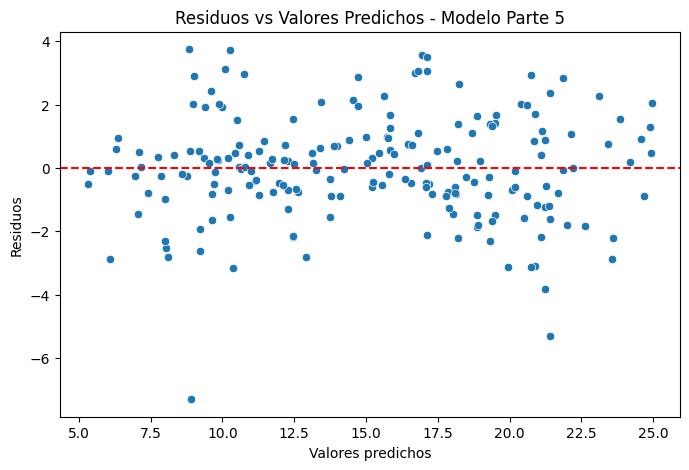

In [56]:
# Graficar residuos contra valores predichos
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred_5, y=residuos_5)

# Línea de referencia en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuos vs Valores Predichos - Modelo Parte 5')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.show()

Interpretación:

En la gráfica podemos observar que los residuos se distribuyen alrededor de la línea horizontal cero. Sin embargo, la dispersión no es completamente uniforme y se presentan significativamente valores alejados.

Esto indica que el supuesto de homocedasticidad no se cumple, ya que la variabilidad de los errores presenta algunas diferencias a lo largo de los valores predichos.

---
---
* El código utiliza sns.scatterplot() para crear una gráfica que compara los valores predichos con los residuos del modelo. También agrega una línea horizontal en cero para observar si los errores se distribuyen aleatoriamente y mantienen una dispersión uniforme.
---
---

**5.4 Q-Q Plot**

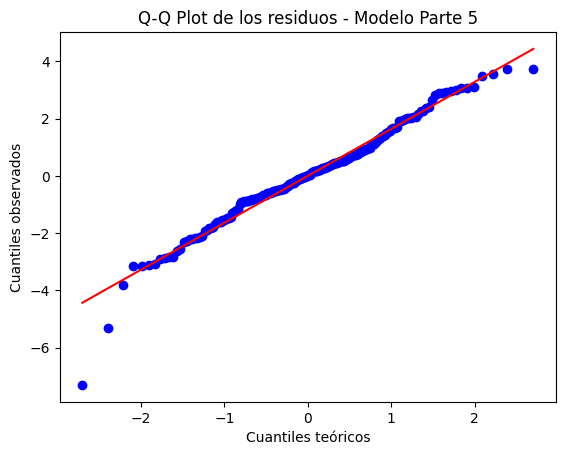

In [57]:
# Q-Q Plot de los residuos
stats.probplot(residuos_5, dist="norm", plot=plt)

plt.title("Q-Q Plot de los residuos - Modelo Parte 5")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.show()

Interpretación:

En el gráfico Q-Q podemos observar que la mayoría de los puntos se encuentran aproximadamente alineados con la línea diagonal roja, lo que indica que los residuos presentan una distribución cercana a la normal.

Sin embargo, en los extremos se observan algunas desviaciones, principalmente en la parte izquierda, lo que puede indicar la presencia de valores atípicos y algunas diferencias respecto a una distribución normal perfecta.

---
---
* El código utiliza stats.probplot() para crear una gráfica Q-Q que compara los residuos del modelo con una distribución normal. Esto permite observar si los puntos siguen aproximadamente la línea diagonal o si presentan desviaciones que indiquen falta de normalidad.
---
---

**5.5 Evaluación del Modelo**

In [58]:
# 1. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 2. Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Entrenar el modelo
modelo_sin_multi = LinearRegression()
modelo_sin_multi.fit(X_train, y_train)

# 4. Obtener predicciones
y_pred_5 = modelo_sin_multi.predict(X_test)

# 5. Calcular métricas
mse_5 = mean_squared_error(y_test, y_pred_5)
rmse_5 = np.sqrt(mse_5)
r2_5 = r2_score(y_test, y_pred_5)

# 6. Mostrar resultados
print("Evaluación del Modelo sin Multicolinealidad")
print("--------------------------------------------")
print("MSE:", mse_5)
print("RMSE:", rmse_5)
print("R²:", r2_5)

Evaluación del Modelo sin Multicolinealidad
--------------------------------------------
MSE: 2.9077569102710896
RMSE: 1.7052146229349223
R²: 0.9059011844150826


Interpretación:

Los resultados de la evaluación deben ser iguales a los obtenidos en la Parte 4, ya que se conservaron las mismas variables independientes y se utilizó la misma división de datos.

Los resultados esperados son:

MSE: 2.9078

RMSE: 1.7052

R²: 0.9059

Esto significa que el modelo explica aproximadamente el 90.59% de la variación de las ventas. Además, el RMSE indica que las predicciones tienen un error promedio aproximado de 1.71 unidades.

En general, el modelo presenta un buen rendimiento para predecir las ventas.

---
---
* El código divide los datos en conjuntos de entrenamiento y prueba utilizando train_test_split() y entrena el modelo con las tres variables independientes. Después, calcula las métricas MSE, RMSE y R² para conocer el nivel de error y qué tan bien predice las ventas.
---
---

**5.6 Visualización de Predicciones**

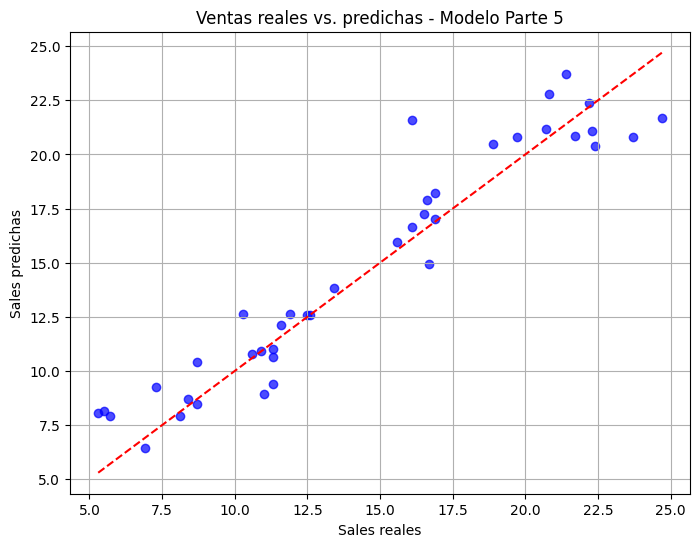

In [59]:
# Crear gráfica de ventas reales vs predichas
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_5, color='blue', alpha=0.7)

# Línea de predicción perfecta
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel('Sales reales')
plt.ylabel('Sales predichas')
plt.title('Ventas reales vs. predichas - Modelo Parte 5')

plt.grid(True)
plt.show()

En la gráfica podemos observar la relación entre las ventas reales y las ventas predichas por el modelo.

La línea roja representa las predicciones perfectas, mientras que los puntos azules representan las predicciones realizadas por el modelo.

La mayoría de los puntos se encuentran cerca de la línea roja, lo que indica que el modelo realiza predicciones bastante cercanas a los valores reales, sin embargo sin cercanas pero siguen existiendo puntos lejandos a la linea roja pero con el mismo patron.

---
---
* El código utiliza plt.scatter() para crear una gráfica que compara las ventas reales con las ventas predichas por el modelo. También agrega una línea roja de referencia que permite identificar qué tan cerca están las predicciones de los valores reales y observar el ajuste del modelo.
---
---

**5.7 Verificar el impacto de los atributos en el modelo**

In [60]:
# 1. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# 2. Agregar constante
X_sm = sm.add_constant(X)

# 3. Ajustar modelo
modelo_sm_5 = sm.OLS(y, X_sm).fit()

# 4. Mostrar resultados
print(modelo_sm_5.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Fri, 30 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        00:55:27   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

Al analizar los valores P>|t| de la tabla obtenemos los siguientes resultados:

TV: Tiene un valor p menor a 0.05, por lo que es estadísticamente significativa.

Radio: Tiene un valor p menor a 0.05, por lo que también es estadísticamente significativa.

Newspaper: Tiene un valor p de 0.954, que es mayor a 0.05, por lo que no es estadísticamente significativa.

Esto significa que la inversión en televisión y radio aporta información importante para explicar las ventas, mientras que la inversión en periódicos no muestra evidencia estadística suficiente de tener un efecto significativo.

---
---
* El código utiliza la librería statsmodels para realizar una regresión lineal múltiple mediante sm.OLS(). Después, muestra una tabla con los coeficientes y valores p, lo que permite identificar cuáles variables son estadísticamente significativas y cuáles aportan información para explicar las ventas.
---
---

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

En la Parte 2 se observó que la variable Newspaper tiene una relación lineal débil con Sales. Además, en la Parte 4.7 se comprobó que su valor p es de 0.954, mayor a 0.05, por lo que no es estadísticamente significativa.

Por esta razón, para construir el modelo de la Parte 6 se eliminará la variable Newspaper y se utilizarán únicamente TV y Radio como variables independientes para predecir las ventas (Sales).

**6.1 Entrenamiento del Modelo (sin Newspaper)**



In [61]:
# 1. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio']]
y = df['Sales']

# 2. Entrenar el modelo
modelo_final = LinearRegression()
modelo_final.fit(X, y)

# 3. Mostrar intercepto y coeficientes
print("Intercepto:", modelo_final.intercept_)

for variable, coeficiente in zip(X.columns, modelo_final.coef_):
    print(f"Coeficiente de {variable}: {coeficiente:.4f}")

Intercepto: 4.630879464097768
Coeficiente de TV: 0.0544
Coeficiente de Radio: 0.1072


Interpretación:

Al eliminar Newspaper, el modelo utiliza solamente las variables TV y Radio para explicar las ventas.

Los coeficientes indican que ambas variables tienen una relación positiva con las ventas. Esto significa que, cuando aumenta la inversión en televisión o radio, también tienden a aumentar las ventas, manteniendo constante la otra variable.

---
---
* El código utiliza LinearRegression() para crear y entrenar un modelo de regresión lineal múltiple utilizando únicamente las variables TV y Radio. Después, muestra el intercepto y los coeficientes para conocer cómo influye cada variable en las ventas.
---
---

**6.2 Normalidad de los residuos**

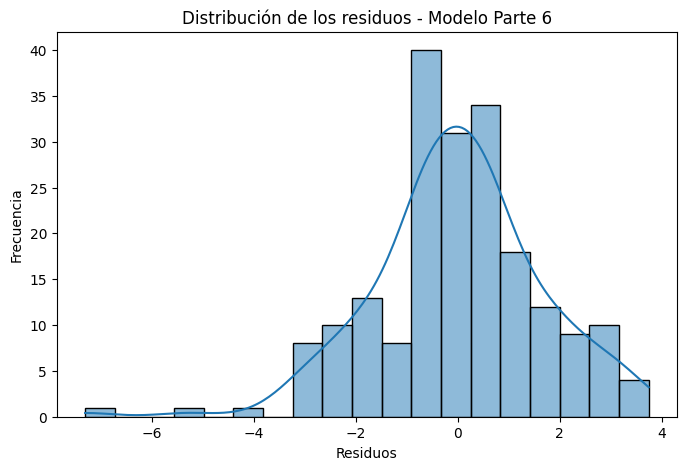

In [62]:
# 1. Obtener predicciones
y_pred_6 = modelo_final.predict(X)

# 2. Calcular residuos
residuos_6 = y - y_pred_6

# 3. Graficar histograma con KDE
plt.figure(figsize=(8, 5))
sns.histplot(residuos_6, kde=True)
plt.title('Distribución de los residuos - Modelo Parte 6')
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.show()

Interpretación:

En el histograma podemos observar que los residuos se concentran principalmente alrededor de cero y presentan una distribución aproximadamente similar a una campana. Sin embargo, existen algunas desviaciones y valores extremos, por lo que no se puede afirmar que sigan una distribución normal perfecta.

El código utiliza modelo_final.predict() para obtener las predicciones y calcula los residuos comparando los valores reales con los estimados. Después, utiliza sns.histplot() para visualizar su distribución mediante un histograma y una curva KDE.

---
---
* El código utiliza modelo_final.predict() para obtener las predicciones y calcula los residuos comparando los valores reales con los estimados. Después, utiliza sns.histplot() para crear un histograma con KDE y observar si los residuos tienen una distribución normal.
---
---

**6.3 Homocedasticidad**

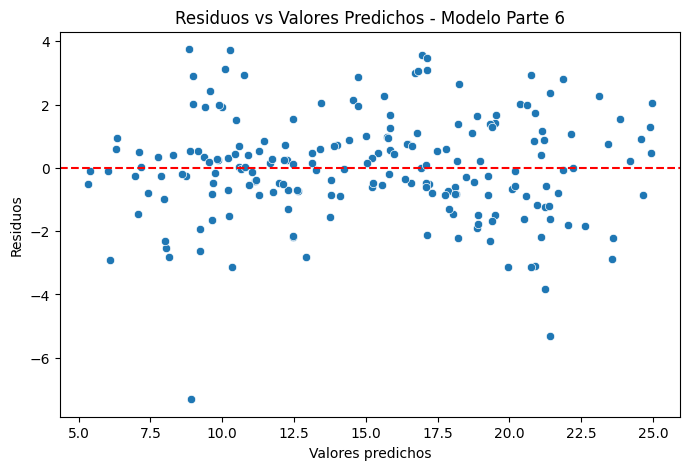

In [63]:
# 1. Graficar residuos contra valores predichos
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred_6, y=residuos_6)

# 2. Línea de referencia en cero
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuos vs Valores Predichos - Modelo Parte 6')
plt.xlabel('Valores predichos')
plt.ylabel('Residuos')
plt.show()

Interpretación:

En la gráfica podemos observar que los residuos se distribuyen alrededor de la línea horizontal cero. Sin embargo, existen algunas diferencias en la dispersión de los errores y algunos puntos alejados, por lo que el supuesto de homocedasticidad no se cumple completamente.

El código utiliza sns.scatterplot() para comparar los valores predichos con los residuos del modelo. También agrega una línea horizontal en cero para identificar si los errores se distribuyen aleatoriamente y mantienen una variabilidad uniforme.

---
---
* El código utiliza sns.scatterplot() para crear una gráfica que compara los valores predichos con los residuos del modelo. También agrega una línea horizontal en cero para identificar si los errores se distribuyen aleatoriamente y mantienen una dispersión uniforme.
---
---

**6.4 Q-Q Plot**

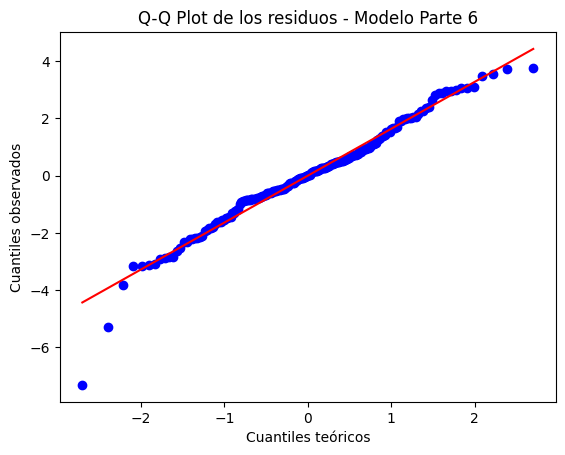

In [64]:
# 1. Q-Q Plot de los residuos
stats.probplot(residuos_6, dist="norm", plot=plt)

plt.title("Q-Q Plot de los residuos - Modelo Parte 6")
plt.xlabel("Cuantiles teóricos")
plt.ylabel("Cuantiles observados")
plt.show()

Interpretación:

En el gráfico Q-Q podemos observar si los residuos siguen aproximadamente una distribución normal. Si la mayoría de los puntos se encuentran cerca de la línea diagonal, significa que existe una aproximación a la normalidad, aunque algunas desviaciones en los extremos pueden indicar valores atípicos.

El código utiliza stats.probplot() para comparar los residuos del modelo con una distribución normal. Esto permite identificar visualmente si los errores siguen una distribución aproximadamente normal o presentan desviaciones.

---
---
* El código utiliza stats.probplot() para crear una gráfica Q-Q que compara los residuos del modelo con una distribución normal. Esto permite observar si los puntos siguen aproximadamente la línea diagonal o presentan desviaciones.
---
---

**6.5 Evaluación del Modelo**

In [65]:
# 1. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio']]
y = df['Sales']

# 2. Dividir los datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Entrenar el modelo
modelo_final = LinearRegression()
modelo_final.fit(X_train, y_train)

# 4. Obtener predicciones
y_pred_6 = modelo_final.predict(X_test)

# 5. Calcular métricas
mse_6 = mean_squared_error(y_test, y_pred_6)
rmse_6 = np.sqrt(mse_6)
r2_6 = r2_score(y_test, y_pred_6)

# 6. Mostrar resultados
print("Evaluación del Modelo Parte 6")
print("------------------------------")
print("MSE:", mse_6)
print("RMSE:", rmse_6)
print("R²:", r2_6)

Evaluación del Modelo Parte 6
------------------------------
MSE: 2.846616122131541
RMSE: 1.6871917858179433
R²: 0.9078797802624651


Interpretación:

Los resultados indican que el modelo presenta un buen rendimiento al utilizar únicamente las variables TV y Radio. El valor de R² es de 0.9079, lo que significa que el modelo explica aproximadamente el 90.79% de la variación de las ventas. Por otro lado, el MSE de 2.8466 y el RMSE de 1.6872 indican que los errores de predicción son relativamente bajos.

En comparación con el modelo anterior de la Parte 4, este modelo presenta una pequeña mejora, ya que aumentó el R² de 0.9059 a 0.9079 y disminuyeron los valores de MSE y RMSE. Esto demuestra que eliminar Newspaper permitió obtener un modelo ligeramente mejor y más sencillo para predecir las ventas.

---
---
* El código divide los datos en conjuntos de entrenamiento y prueba, utilizando únicamente TV y Radio para entrenar el modelo. Después, calcula las métricas MSE, RMSE y R² para conocer el nivel de error y qué tan bien predice las ventas.
---
---

**6.6 Visualización de Predicciones**

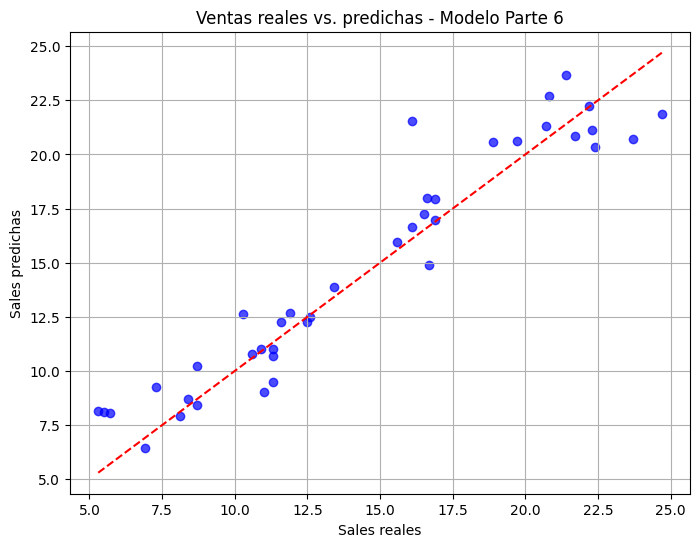

In [66]:
# 1. Crear gráfica de dispersión
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_6, color='blue', alpha=0.7)

# 2. Línea de referencia (predicción perfecta)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel('Sales reales')
plt.ylabel('Sales predichas')
plt.title('Ventas reales vs. predichas - Modelo Parte 6')

plt.grid(True)
plt.show()

En la gráfica podemos observar la relación entre las ventas reales y las ventas predichas por el modelo.

La línea roja representa las predicciones perfectas, mientras que los puntos azules representan las predicciones realizadas por el modelo.

La mayoría de los puntos se encuentran cerca de la línea roja, lo que indica que el modelo realiza predicciones bastante cercanas a los valores reales, sin embargo sin cercanas pero siguen existiendo puntos lejandos a la linea roja pero con el mismo patron.

---
---
* El código utiliza plt.scatter() para crear una gráfica que compara las ventas reales con las ventas predichas por el modelo. También agrega una línea roja de referencia para identificar qué tan precisas son las predicciones.
---
---

**6.7 Verificar el impacto de los atributos en el modelo**

In [67]:
# 1. Seleccionar variables independientes y dependiente
X = df[['TV', 'Radio']]
y = df['Sales']

# 2. Agregar constante
X_sm = sm.add_constant(X)

# 3. Ajustar modelo de regresión
modelo_sm_6 = sm.OLS(y, X_sm).fit()

# 4. Mostrar resultados
print(modelo_sm_6.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        01:13:53   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

Interpretación:

Al analizar los valores P>|t| de la tabla, podemos observar que las variables TV y Radio tienen valores p de 0.000, los cuales son menores a 0.05. Esto significa que ambas variables son estadísticamente significativas y tienen una relación importante con las ventas.

La variable TV tiene un coeficiente de 0.0544, mientras que Radio tiene un coeficiente de 0.1072. Esto indica que ambas influyen positivamente en las ventas, manteniendo constante la otra variable. Además, el R² de 0.903 indica que el modelo explica aproximadamente el 90.3% de la variación de las ventas.

---
---
* El código utiliza statsmodels y sm.OLS() para realizar una regresión lineal múltiple con las variables TV y Radio. Finalmente, muestra una tabla con los coeficientes y valores p para identificar cuáles variables son estadísticamente significativas y cómo influyen en las ventas.
---
---

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

Al comparar los tres modelos construidos, podemos concluir que el modelo de la Parte 6 fue el que presentó el mejor rendimiento, ya que utiliza únicamente las variables TV y Radio, eliminando Newspaper por su baja relación lineal con las ventas y su falta de significancia estadística.

Este modelo obtuvo un MSE de 2.8466, un RMSE de 1.6872 y un R² de 0.9079, lo que significa que explica aproximadamente el 90.79% de la variación de las ventas. Además, presentó mejores resultados que los modelos de las Partes 4 y 5.

Respecto al atributo que tiene mayor influencia en las ventas, podemos observar que Radio presenta el coeficiente más alto (0.1072), mientras que TV tiene un coeficiente de 0.0544. Esto indica que, manteniendo constante la inversión en el otro medio, la publicidad en radio tiene un mayor efecto estimado por unidad de inversión sobre las ventas.

En conclusión, el modelo de la Parte 6 es la mejor alternativa porque es más sencillo, mantiene un alto poder explicativo y utiliza únicamente variables estadísticamente significativas. Por lo tanto, se recomienda enfocar las estrategias publicitarias principalmente en radio y televisión para mejorar las ventas.